Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        

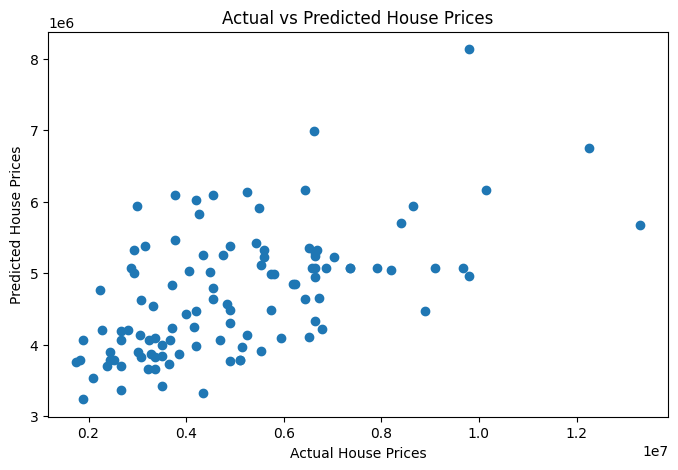

In [8]:
from google.colab import drive
drive.mount('/content/drive')

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 2. Load dataset
df = pd.read_csv('/content/drive/MyDrive/ML Practical/Housing.csv')

# Check dataset
print(df.head())
print(df.columns)

# 3. Select input feature and target
X = df[['area']]
y = df['price']

# 4. Handle missing values
X = X.fillna(X.mean())
y = y.fillna(y.mean())

# 5. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 6. Create and train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 7. Predict house prices
y_pred = model.predict(X_test)

# 8. Calculate R² score
r2 = r2_score(y_test, y_pred)
print("R² Score:", r2)

# 9. Display actual and predicted prices
result = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(result.head(10))

# 10. Plot predicted vs actual values
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred)
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.show()